# NexaTel — Phase 3: Churn KPI Calculations
## Anushka Tyagi

Calculate business KPIs using the cleaned Phase 1 data.
Reporting periods, metric definitions, and assumptions are documented
alongside each calculation.

In [1]:
import pandas as pd
from pathlib import Path

# Load cleaned Phase 1 tables
clean_folder = Path("phase1_output") / "cleaned_data"

if not clean_folder.is_dir():
    raise FileNotFoundError(
        "Cleaned data folder not found. Keep this notebook inside "
        "NEXATEL_PROJECT, beside phase1_output."
    )

csv_files = sorted(clean_folder.glob("*.csv"))

if len(csv_files) != 24:
    raise ValueError(
        f"Expected 24 cleaned CSV files, but found {len(csv_files)}."
    )

kpi_tables = {
    file.stem: pd.read_csv(file)
    for file in csv_files
}

# Create a folder for KPI results
output_folder = Path("phase3_output")
output_folder.mkdir(parents=True, exist_ok=True)

# Show table sizes
table_summary = pd.DataFrame([
    {
        "Table": name,
        "Rows": len(table),
        "Columns": len(table.columns)
    }
    for name, table in kpi_tables.items()
])

display(table_summary)

# Validate the customer base
customers = kpi_tables["customers"].copy()

assert customers["customer_id"].notna().all(), "Missing customer IDs."
assert customers["customer_id"].is_unique, "Duplicate customer IDs."
assert customers["customer_status"].isin(
    ["Active", "Churned"]
).all(), "Unexpected customer status."

print("Tables loaded:", len(kpi_tables))
print("Total customers:", len(customers))
display(customers["customer_status"].value_counts())

# Inspect available fields before defining KPI calculations
print("\nAVAILABLE COLUMNS")
for name, table in kpi_tables.items():
    print(f"\n{name}:")
    print(", ".join(table.columns))

print("\nKPI results will be saved to:", output_folder.resolve())

,Table,Rows,Columns
0,billing,114969,13
1,cities,68,8
2,complaints,16584,7
3,contracts,10607,9
4,customer_feedback,28499,7
5,customers,19000,32
6,data_quality_issue_log,20,3
7,devices,19000,8
8,employees,800,9
9,marketing_campaigns,40,9


Tables loaded: 24
Total customers: 19000


customer_status
Active     15494
Churned     3506
Name: count, dtype: int64


AVAILABLE COLUMNS

billing:
invoice_id, customer_id, billing_date, billing_period_month, base_amount_inr, gst_amount_inr, total_amount_inr, due_date, payment_status, original_total_amount_inr, original_gst_amount_inr, original_billing_date, billing_date_inferred

cities:
city_id, city_name, state_id, state_name, zone, region_id, tier, pin_prefix

complaints:
complaint_id, customer_id, complaint_date, complaint_type, severity, status, resolution_date

contracts:
contract_id, customer_id, plan_id, contract_type, contract_length_months, start_date, end_date, auto_renew, renewal_status

customer_feedback:
feedback_id, customer_id, feedback_date, csat_score, nps_score, channel, feedback_category

customers:
customer_id, first_name, last_name, gender, date_of_birth, age, email, phone_number, address, city_id, city_name, state_id, pin_code, city_tier, region_id, occupation, annual_income_inr, customer_segment, product_line, plan_id, acquisition_channel, acquisition_date, tenure_months, custo

In [2]:
# Step 2: Validate customer dates and inspect reporting periods
customer_dates = customers.copy()

for column in ["acquisition_date", "churn_date"]:
    original = customer_dates[column].astype("string").str.strip()
    has_value = original.notna() & original.ne("")

    # Phase 1 cleaned dates are saved in YYYY-MM-DD format
    parsed = pd.to_datetime(
        original,
        format="%Y-%m-%d",
        errors="coerce"
    )

    invalid = has_value & parsed.isna()

    assert not invalid.any(), (
        f"{column}: {invalid.sum()} dates could not be parsed."
    )

    customer_dates[column] = parsed

acquired = customer_dates["acquisition_date"]
churned_on = customer_dates["churn_date"]
status = customer_dates["customer_status"]

date_checks = pd.Series({
    "Missing acquisition dates": acquired.isna().sum(),
    "Churned customers without churn dates": (
        status.eq("Churned") & churned_on.isna()
    ).sum(),
    "Active customers with churn dates": (
        status.eq("Active") & churned_on.notna()
    ).sum(),
    "Churn dates before acquisition dates": (
        churned_on < acquired
    ).sum()
}, name="Customers affected")

display(date_checks.to_frame())

date_coverage = pd.DataFrame({
    "Earliest date": [acquired.min(), churned_on.min()],
    "Latest date": [acquired.max(), churned_on.max()]
}, index=["Acquisition date", "Churn date"])

display(date_coverage)

# Count recorded customer losses by month
print("Recorded churn events by month:")
display(
    churned_on.dropna()
    .dt.to_period("M")
    .value_counts()
    .sort_index()
    .rename_axis("Month")
    .to_frame("Churned customers")
)

# Inspect billing periods to help choose a reporting month
print("Billing periods available:")
display(
    kpi_tables["billing"]["billing_period_month"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Billing period")
    .to_frame("Invoice records")
)

,Customers affected
Missing acquisition dates,0
Churned customers without churn dates,0
Active customers with churn dates,0
Churn dates before acquisition dates,0


,Earliest date,Latest date
Acquisition date,2014-01-01,2026-03-01
Churn date,2014-02-23,2026-03-30


Recorded churn events by month:


,Churned customers
Month,
2014-02,1
2014-03,3
2014-05,1
2014-06,4
2014-07,1
...,...
2025-11,113
2025-12,109
2026-01,124


Billing periods available:


,Invoice records
Billing period,
01-2015,20
01-2016,29
01-2017,27
01-2018,49
01-2019,63
...,...
12-2021,113
12-2022,140
12-2023,238


# KPI-1 Customer Churn Rate	Customers Lost / Customers at Start × 100	Target < 2.1% monthly. The headline retention metric.

In [3]:
# KPI 1: Customer churn rate — March 2026
report_start = pd.Timestamp("2026-03-01")
report_end = pd.Timestamp("2026-04-01")  # Exclusive end boundary

acquired = customer_dates["acquisition_date"]
churned_on = customer_dates["churn_date"]

# Opening base: acquired before March and not churned before March
opening_base = (
    acquired.lt(report_start)
    & (churned_on.isna() | churned_on.ge(report_start))
)

# All recorded churn events during March
churn_in_month = (
    churned_on.ge(report_start)
    & churned_on.lt(report_end)
)

# Opening-base customers lost during March
opening_base_lost = opening_base & churn_in_month

# Separately identify customers acquired and lost within March
new_and_churned = (
    acquired.ge(report_start)
    & acquired.lt(report_end)
    & churn_in_month
)

customers_at_start = int(opening_base.sum())
customers_lost = int(opening_base_lost.sum())

assert customers_at_start > 0, "Opening customer base is empty."
assert customers_lost <= customers_at_start
assert (
    customers_lost + int(new_and_churned.sum())
    == int(churn_in_month.sum())
), "Monthly churn events do not reconcile."

churn_rate_pct = customers_lost / customers_at_start * 100

churn_kpi = pd.DataFrame([{
    "Reporting month": "2026-03",
    "Customers at start": customers_at_start,
    "Opening-base customers lost": customers_lost,
    "All churn events in month": int(churn_in_month.sum()),
    "Acquired and churned in month": int(new_and_churned.sum()),
    "Customer churn rate (%)": churn_rate_pct,
    "Target (%)": 2.1,
    "Below target": churn_rate_pct < 2.1
}])

display(churn_kpi.round(3))

churn_kpi.to_csv(
    output_folder / "01_customer_churn_rate.csv",
    index=False
)

print(f"March opening-base churn rate: {churn_rate_pct:.3f}%")
print("Saved: phase3_output/01_customer_churn_rate.csv")

,Reporting month,Customers at start,Opening-base customers lost,All churn events in month,Acquired and churned in month,Customer churn rate (%),Target (%),Below target
0,2026-03,15688,196,198,2,1.249,2.1,True


March opening-base churn rate: 1.249%
Saved: phase3_output/01_customer_churn_rate.csv


## KPI 1 — Customer Churn Rate: Observation

March 2026 opening-base churn was 1.249%: 196 of the 15,688
customers present at the start of March churned during the month.
This is below the 2.1% monthly target, assuming complete March data.
Two additional customers joined and churned within March and are
reported separately from opening-base churn.

# KPI-2 Customer Retention Rate	(End - New) / Start × 100	The positive mirror of churn.

In [4]:
# KPI 2: Retention of March's opening customer base

# Customers remaining immediately before April 1
closing_base = (
    acquired.lt(report_end)
    & (churned_on.isna() | churned_on.ge(report_end))
)

# March acquisitions
new_in_month = (
    acquired.ge(report_start)
    & acquired.lt(report_end)
)

# New customers who remain in the closing base
new_customers_remaining = new_in_month & closing_base

# Opening-base customers still present at month-end
opening_customers_retained = opening_base & closing_base

customers_at_end = int(closing_base.sum())
new_remaining = int(new_customers_remaining.sum())
retained_customers = int(opening_customers_retained.sum())

assert retained_customers == customers_at_start - customers_lost
assert retained_customers == customers_at_end - new_remaining

retention_rate_pct = (
    retained_customers / customers_at_start * 100
)

assert abs(retention_rate_pct + churn_rate_pct - 100) < 1e-8

retention_kpi = pd.DataFrame([{
    "Reporting month": "2026-03",
    "Customers at start": customers_at_start,
    "Customers at end": customers_at_end,
    "New customers acquired": int(new_in_month.sum()),
    "New customers remaining at end": new_remaining,
    "Opening-base customers retained": retained_customers,
    "Customer retention rate (%)": retention_rate_pct
}])

display(retention_kpi.round(3))

retention_kpi.to_csv(
    output_folder / "02_customer_retention_rate.csv",
    index=False
)

print(f"March opening-base retention rate: {retention_rate_pct:.3f}%")

,Reporting month,Customers at start,Customers at end,New customers acquired,New customers remaining at end,Opening-base customers retained,Customer retention rate (%)
0,2026-03,15688,15494,4,2,15492,98.751


March opening-base retention rate: 98.751%


## KPI 2 — Customer Retention Rate: Observation

In March 2026, 15,492 of the 15,688 opening customers were retained,
giving an opening-base retention rate of 98.751%.
Four customers joined during March, but only two remained at month-end,
bringing the closing customer base to 15,494.
Retention and churn sum to 100% for the same opening customer base.

# KPI-3 ARPU	Total Recurring Revenue / Avg Active Subscribers	Monetisation per subscriber per month.

In [5]:
# Inspect March billing before calculating ARPU
billing = kpi_tables["billing"].copy()

billing["billing_month"] = pd.to_datetime(
    billing["billing_period_month"].astype("string").str.strip(),
    format="%m-%Y",
    errors="coerce"
)

assert billing["billing_month"].notna().all(), (
    "Missing or invalid billing periods."
)

billing["base_amount_inr"] = pd.to_numeric(
    billing["base_amount_inr"], errors="coerce"
)

assert billing["base_amount_inr"].notna().all(), (
    "Missing or invalid base amounts."
)

march_billing = billing.loc[
    billing["billing_month"].eq(report_start)
].copy()

assert not march_billing.empty, "No March billing records found."

# Customers present for at least part of March
present_in_month = (
    acquired.lt(report_end)
    & (churned_on.isna() | churned_on.ge(report_start))
)

eligible_ids = customer_dates.loc[
    present_in_month, "customer_id"
]

billing_checks = pd.Series({
    "March invoice records": len(march_billing),
    "Unique customers billed": march_billing["customer_id"].nunique(),
    "Duplicate invoice IDs": march_billing["invoice_id"].duplicated().sum(),
    "Missing customer IDs": march_billing["customer_id"].isna().sum(),
    "Invoices outside reconstructed March customer base": (
        ~march_billing["customer_id"].isin(eligible_ids)
    ).sum(),
    "March customers without an invoice": (
        ~eligible_ids.isin(march_billing["customer_id"])
    ).sum(),
    "Negative base amounts": (
        march_billing["base_amount_inr"].lt(0)
    ).sum()
}, name="Count")

display(billing_checks.to_frame())

print("March base amounts, excluding GST:")
display(march_billing["base_amount_inr"].describe().round(2))

print("Billing coverage by customer product line:")
coverage = customer_dates.loc[
    present_in_month, ["customer_id", "product_line"]
].copy()

coverage["has_march_invoice"] = coverage["customer_id"].isin(
    march_billing["customer_id"]
)

display(
    coverage.groupby("product_line", dropna=False)
    .agg(
        Customers=("customer_id", "size"),
        Customers_billed=("has_march_invoice", "sum")
    )
)

,Count
March invoice records,16855
Unique customers billed,8485
Duplicate invoice IDs,0
Missing customer IDs,0
Invoices outside reconstructed March customer base,0
March customers without an invoice,7207
Negative base amounts,0


March base amounts, excluding GST:


count    16855.00
mean      1316.10
std       1718.67
min         81.61
25%        589.38
50%        847.51
75%       1153.20
max       9781.52
Name: base_amount_inr, dtype: float64

Billing coverage by customer product line:


,Customers,Customers_billed
product_line,,
5G,1252,1252
Enterprise,765,765
Fiber Broadband,1862,1862
IoT Solutions,472,472
OTT Bundles,721,721
Postpaid Mobile,3126,3126
Prepaid Mobile,7207,0
Smart Home,287,287


In [6]:
# Check how many March invoices each customer has
invoice_counts = march_billing.groupby("customer_id").size()

print("March invoices per customer:")
display(
    invoice_counts.value_counts()
    .sort_index()
    .rename_axis("Invoices per customer")
    .to_frame("Number of customers")
)

# Show invoice details for three customers with multiple invoices
example_ids = invoice_counts[invoice_counts > 1].head(3).index

print("Examples of multiple March invoices:")
display(
    march_billing.loc[
        march_billing["customer_id"].isin(example_ids),
        [
            "customer_id", "invoice_id", "billing_date",
            "billing_period_month", "base_amount_inr",
            "total_amount_inr", "payment_status"
        ]
    ].sort_values(["customer_id", "billing_date"])
)

# Inspect prepaid recharge coverage for March
recharges = kpi_tables["recharges"].copy()

recharges["recharge_date"] = pd.to_datetime(
    recharges["recharge_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

recharges["amount_inr"] = pd.to_numeric(
    recharges["amount_inr"], errors="coerce"
)

assert recharges["recharge_date"].notna().all(), (
    "Missing or invalid recharge dates."
)
assert recharges["amount_inr"].notna().all(), (
    "Missing or invalid recharge amounts."
)

march_recharges = recharges.loc[
    recharges["recharge_date"].ge(report_start)
    & recharges["recharge_date"].lt(report_end)
].copy()

print("March recharge checks:")
display(pd.Series({
    "Recharge transactions": len(march_recharges),
    "Unique customers": march_recharges["customer_id"].nunique(),
    "Duplicate recharge IDs":
        march_recharges["recharge_id"].duplicated().sum(),
    "Transactions outside March customer base":
        (~march_recharges["customer_id"].isin(eligible_ids)).sum(),
    "Negative recharge amounts":
        march_recharges["amount_inr"].lt(0).sum(),
    "Total recorded recharge amount (INR)":
        march_recharges["amount_inr"].sum()
}, name="Value").to_frame())

print("Product lines of customers with March recharges:")
display(
    march_recharges[["customer_id"]]
    .drop_duplicates()
    .merge(
        customers[["customer_id", "product_line"]],
        on="customer_id",
        how="left",
        validate="one_to_one"
    )["product_line"]
    .value_counts(dropna=False)
)

March invoices per customer:


,Number of customers
Invoices per customer,
1,115
2,8370


Examples of multiple March invoices:


,customer_id,invoice_id,billing_date,billing_period_month,base_amount_inr,total_amount_inr,payment_status
1,C0000002,INV00000002,2026-03-01,03-2026,1396.28,1647.61,Overdue
0,C0000002,INV00000001,2026-03-31,03-2026,1490.77,1759.11,Paid
14,C0000006,INV00000015,2026-03-01,03-2026,794.60,937.63,Overdue
13,C0000006,INV00000014,2026-03-31,03-2026,787.95,929.78,Paid
38,C0000009,INV00000039,2026-03-01,03-2026,904.90,1067.78,Unpaid
37,C0000009,INV00000038,2026-03-31,03-2026,868.70,1025.07,Unpaid


March recharge checks:


,Value
Recharge transactions,2227.00
Unique customers,1768.00
Duplicate recharge IDs,0.00
Transactions outside March customer base,1.00
Negative recharge amounts,0.00
Total recorded recharge amount (INR),701241.25


Product lines of customers with March recharges:


product_line
Prepaid Mobile    1768
Name: count, dtype: int64

In [7]:
# KPI 3: Provisional billed ARPU — non-prepaid customers
# Assumption: recorded product_line applies throughout March.

assert customer_dates["product_line"].notna().all()

non_prepaid = customer_dates["product_line"].ne("Prepaid Mobile")

opening_non_prepaid = int((opening_base & non_prepaid).sum())
closing_non_prepaid = int((closing_base & non_prepaid).sum())

# Approximation of average active customers
avg_non_prepaid = (
    opening_non_prepaid + closing_non_prepaid
) / 2

assert avg_non_prepaid > 0

non_prepaid_ids = customer_dates.loc[
    non_prepaid, "customer_id"
]

assert march_billing["customer_id"].isin(non_prepaid_ids).all()
assert march_billing["invoice_id"].is_unique

# Keep all distinct invoices; do not remove records without evidence
march_billed_amount = march_billing["base_amount_inr"].sum()

billed_arpu_proxy = march_billed_amount / avg_non_prepaid

arpu_kpi = pd.DataFrame([{
    "Reporting month": "2026-03",
    "Metric": "Non-prepaid billed ARPU proxy",
    "Opening customers": opening_non_prepaid,
    "Closing customers": closing_non_prepaid,
    "Average active customers": avg_non_prepaid,
    "Billed amount excluding GST (INR)": march_billed_amount,
    "ARPU proxy (INR)": billed_arpu_proxy,
    "Status": "Provisional: recurring-charge composition unverified"
}])

display(arpu_kpi.round(2))

arpu_kpi.to_csv(
    output_folder / "03_non_prepaid_billed_arpu_proxy.csv",
    index=False
)

# Inspect and save the recharge exception
recharge_exceptions = march_recharges.loc[
    ~march_recharges["customer_id"].isin(eligible_ids)
].merge(
    customer_dates[
        ["customer_id", "acquisition_date",
         "churn_date", "customer_status"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Recharge outside the reconstructed March customer base:")
display(recharge_exceptions)

recharge_exceptions.to_csv(
    output_folder / "march_recharge_exceptions.csv",
    index=False
)

,Reporting month,Metric,Opening customers,Closing customers,Average active customers,Billed amount excluding GST (INR),ARPU proxy (INR),Status
0,2026-03,Non-prepaid billed ARPU proxy,8483,8396,8439.5,22182783.84,2628.45,Provisional: recurring-charge composition unve...


Recharge outside the reconstructed March customer base:


,recharge_id,customer_id,recharge_date,amount_inr,plan_id,payment_method,acquisition_date,churn_date,customer_status
0,RC00141759,C0018383,2026-03-09,275.29,PL002,Wallet,2026-02-20,2026-02-24,Churned


### KPI 3 — Observation

March 2026 non-prepaid billed ARPU was ₹2,628.45, calculated using ₹22,182,783.84 in recorded invoice base amounts excluding GST and an average opening/closing customer base of 8,439.5. This is a provisional billed ARPU proxy because recurring-charge composition is unverified; prepaid recharge amounts are excluded. One ₹275.29 recharge occurred after the customer's recorded churn date and was flagged for review.

# KPI-4 Customer Lifetime Value	ARPU × Gross Margin % × (1 / Churn Rate)	Premium should be far higher than Mass.

In [8]:
# KPI 4: Illustrative CLV scenarios — non-prepaid customers
# Gross margins below are assumptions, not measured company margins.
# Uses the provisional billed ARPU calculated in KPI 3.

non_prepaid_opening = int((opening_base & non_prepaid).sum())
non_prepaid_lost = int((opening_base_lost & non_prepaid).sum())

assert non_prepaid_opening > 0

# Decimal churn rate: do not multiply by 100 in the CLV formula.
non_prepaid_churn_rate = (
    non_prepaid_lost / non_prepaid_opening
)

assert 0 < non_prepaid_churn_rate <= 1, (
    "CLV requires a positive churn rate."
)

clv_rows = []

for gross_margin in [0.30, 0.40, 0.50]:
    estimated_clv = (
        billed_arpu_proxy
        * gross_margin
        / non_prepaid_churn_rate
    )

    clv_rows.append({
        "Reporting month": "2026-03",
        "Customer scope": "Non-prepaid",
        "Billed ARPU proxy (INR)": billed_arpu_proxy,
        "Opening customers": non_prepaid_opening,
        "Opening-base customers lost": non_prepaid_lost,
        "Monthly churn (%)": non_prepaid_churn_rate * 100,
        "Assumed gross margin (%)": gross_margin * 100,
        "Illustrative CLV (INR)": estimated_clv,
        "Status": "Scenario estimate using provisional billed ARPU"
    })

clv_kpi = pd.DataFrame(clv_rows)

display(clv_kpi.round(2))

clv_kpi.to_csv(
    output_folder / "04_clv_scenarios_non_prepaid.csv",
    index=False
)

print("Saved: phase3_output/04_clv_scenarios_non_prepaid.csv")

,Reporting month,Customer scope,Billed ARPU proxy (INR),Opening customers,Opening-base customers lost,Monthly churn (%),Assumed gross margin (%),Illustrative CLV (INR),Status
0,2026-03,Non-prepaid,2628.45,8483,88,1.04,30.0,76012.91,Scenario estimate using provisional billed ARPU
1,2026-03,Non-prepaid,2628.45,8483,88,1.04,40.0,101350.55,Scenario estimate using provisional billed ARPU
2,2026-03,Non-prepaid,2628.45,8483,88,1.04,50.0,126688.19,Scenario estimate using provisional billed ARPU


Saved: phase3_output/04_clv_scenarios_non_prepaid.csv


In [9]:
# CLV comparison by segment — non-prepaid customers only
# Assumes recorded segment/product line applies throughout March.
# 40% gross margin is illustrative, not an observed company value.

assert customer_dates["customer_segment"].notna().all()

segment_clv_rows = []

for segment in ["Mass", "Value", "Premium", "Enterprise"]:
    segment_mask = (
        non_prepaid
        & customer_dates["customer_segment"].eq(segment)
    )

    segment_ids = customer_dates.loc[segment_mask, "customer_id"]

    opening = int((opening_base & segment_mask).sum())
    closing = int((closing_base & segment_mask).sum())
    lost = int((opening_base_lost & segment_mask).sum())

    average_customers = (opening + closing) / 2

    billed_amount = march_billing.loc[
        march_billing["customer_id"].isin(segment_ids),
        "base_amount_inr"
    ].sum()

    arpu = (
        billed_amount / average_customers
        if average_customers > 0 else float("nan")
    )

    churn = lost / opening if opening > 0 else float("nan")

    clv = (
        arpu * 0.40 / churn
        if churn > 0 else float("nan")
    )

    segment_clv_rows.append({
        "Reporting month": "2026-03",
        "Customer scope": "Non-prepaid",
        "Segment": segment,
        "Opening customers": opening,
        "Closing customers": closing,
        "Opening-base customers lost": lost,
        "Billed ARPU proxy (INR)": arpu,
        "Monthly churn (%)": churn * 100,
        "Assumed gross margin (%)": 40,
        "Illustrative CLV (INR)": clv
    })

segment_clv = pd.DataFrame(segment_clv_rows)

display(segment_clv.round(2))

segment_clv.to_csv(
    output_folder / "04_clv_by_segment_non_prepaid.csv",
    index=False
)

print("CLV values are scenario estimates using provisional billed ARPU.")
print("NaN means CLV cannot be estimated with the available denominator.")

,Reporting month,Customer scope,Segment,Opening customers,Closing customers,Opening-base customers lost,Billed ARPU proxy (INR),Monthly churn (%),Assumed gross margin (%),Illustrative CLV (INR)
0,2026-03,Non-prepaid,Mass,0,0,0,NaN,NaN,40,NaN
1,2026-03,Non-prepaid,Value,1304,1289,15,1047.64,1.15,40,36429.98
2,2026-03,Non-prepaid,Premium,5942,5883,60,1856.31,1.01,40,73534.47
3,2026-03,Non-prepaid,Enterprise,1237,1224,13,8004.15,1.05,40,304650.30


CLV values are scenario estimates using provisional billed ARPU.
NaN means CLV cannot be estimated with the available denominator.


### KPI 4 — Observation

At an assumed 40% gross margin, illustrative non-prepaid CLV is ₹36,429.98 for Value, ₹73,534.47 for Premium, and ₹304,650.30 for Enterprise. Mass CLV cannot be estimated within this scope because its opening and closing non-prepaid customer counts are zero, so the Premium-versus-Mass expectation cannot be tested. These scenarios use provisional billed ARPU and assume March churn and ARPU remain constant over time.

# KPI-5 Revenue Lost to Churn	Churned Customers × their ARPU	Translates churn into rupees at risk.

In [10]:
# KPI 5: Check prior-month billing for March churned customers
# Scope: non-prepaid; includes all March churn events.
# February billed amounts are a proxy, not verified recurring revenue.

previous_month = report_start - pd.DateOffset(months=1)

lost_customer_detail = customer_dates.loc[
    churn_in_month & non_prepaid,
    ["customer_id", "customer_segment", "acquisition_date", "churn_date"]
].copy()

february_billing = billing.loc[
    billing["billing_month"].eq(previous_month)
].copy()

assert february_billing["invoice_id"].is_unique
assert february_billing["base_amount_inr"].notna().all()

february_by_customer = (
    february_billing.groupby("customer_id", as_index=False)
    .agg(
        February_invoice_count=("invoice_id", "size"),
        February_billed_INR=("base_amount_inr", "sum")
    )
)

lost_customer_detail = lost_customer_detail.merge(
    february_by_customer,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

has_prior_bill = lost_customer_detail["February_invoice_count"].notna()

coverage_check = pd.Series({
    "March churned non-prepaid customers": len(lost_customer_detail),
    "Customers with February invoices": int(has_prior_bill.sum()),
    "Customers without February invoices": int((~has_prior_bill).sum()),
    "February billed amount for covered customers (INR)":
        lost_customer_detail.loc[
            has_prior_bill, "February_billed_INR"
        ].sum(min_count=1)
}, name="Value")

display(coverage_check.to_frame().round(2))

print("Customers without February invoices:")
display(lost_customer_detail.loc[~has_prior_bill])

lost_customer_detail.to_csv(
    output_folder / "05_churned_customer_billing_coverage.csv",
    index=False
)

,Value
March churned non-prepaid customers,89.00
Customers with February invoices,70.00
Customers without February invoices,19.00
February billed amount for covered customers (INR),73403.41


Customers without February invoices:


,customer_id,customer_segment,acquisition_date,churn_date,February_invoice_count,February_billed_INR
0,C0000149,Premium,2026-01-17,2026-03-16,NaN,NaN
3,C0000361,Premium,2025-03-29,2026-03-01,NaN,NaN
4,C0000788,Premium,2017-02-25,2026-03-01,NaN,NaN
7,C0001241,Premium,2026-01-11,2026-03-02,NaN,NaN
17,C0002123,Value,2026-02-26,2026-03-06,NaN,NaN
23,C0003460,Enterprise,2024-04-16,2026-03-01,NaN,NaN
26,C0004486,Enterprise,2026-02-08,2026-03-12,NaN,NaN
38,C0007549,Value,2026-02-10,2026-03-11,NaN,NaN
39,C0008227,Premium,2026-02-13,2026-03-07,NaN,NaN
40,C0008736,Premium,2026-02-03,2026-03-09,NaN,NaN


In [11]:
# KPI 5: Partial monthly revenue-loss proxy
# Uses February billing for covered March churned non-prepaid customers.

covered_customers = int(has_prior_bill.sum())
total_lost_customers = len(lost_customer_detail)
missing_customers = total_lost_customers - covered_customers

assert covered_customers > 0
assert total_lost_customers > 0

covered_amount = lost_customer_detail.loc[
    has_prior_bill, "February_billed_INR"
].sum()

lost_customer_arpu_proxy = covered_amount / covered_customers

# Churned customers × their prior-month average billed amount
revenue_lost_proxy = covered_customers * lost_customer_arpu_proxy

revenue_lost_kpi = pd.DataFrame([{
    "Reporting month": "2026-03",
    "Customer scope": "Non-prepaid",
    "March churned customers": total_lost_customers,
    "Customers with February billing": covered_customers,
    "Customers without February billing": missing_customers,
    "Coverage (%)": covered_customers / total_lost_customers * 100,
    "Prior-month billed ARPU of covered customers (INR)":
        lost_customer_arpu_proxy,
    "Partial monthly revenue-loss proxy (INR)": revenue_lost_proxy,
    "Status": "Partial estimate; excludes GST and prepaid customers"
}])

display(revenue_lost_kpi.round(2))

revenue_lost_kpi.to_csv(
    output_folder / "05_revenue_lost_to_churn_proxy.csv",
    index=False
)

print("Saved: phase3_output/05_revenue_lost_to_churn_proxy.csv")

,Reporting month,Customer scope,March churned customers,Customers with February billing,Customers without February billing,Coverage (%),Prior-month billed ARPU of covered customers (INR),Partial monthly revenue-loss proxy (INR),Status
0,2026-03,Non-prepaid,89,70,19,78.65,1048.62,73403.41,Partial estimate; excludes GST and prepaid cus...


Saved: phase3_output/05_revenue_lost_to_churn_proxy.csv


### KPI 5 — Observation

Of 89 non-prepaid customers who churned in March, 70 had February invoices, giving 78.65% coverage. Their average February billed amount was ₹1,048.62 excluding GST, producing a partial monthly revenue-loss proxy of ₹73,403.41. This estimate excludes 19 customers without February invoices and all prepaid customers; it represents prior-month billing associated with churned customers, not verified recurring revenue lost or an actual March accounting loss.

# KPI-6 Monthly Recurring Revenue	Sum of active recurring charges	Size of the predictable revenue base.

In [12]:
# KPI 6: Subscription checks for March-end MRR

subscriptions = kpi_tables["subscriptions"].copy()

assert subscriptions["subscription_id"].notna().all()
assert subscriptions["subscription_id"].is_unique

for column in ["start_date", "end_date"]:
    original = subscriptions[column].astype("string").str.strip()
    has_value = original.notna() & original.ne("")

    parsed = pd.to_datetime(
        original, format="%Y-%m-%d", errors="coerce"
    )

    assert not (has_value & parsed.isna()).any(), (
        f"Unparseable values in {column}"
    )

    subscriptions[column] = parsed

subscriptions["monthly_charge_inr"] = pd.to_numeric(
    subscriptions["monthly_charge_inr"], errors="coerce"
)

assert subscriptions["start_date"].notna().all()
assert subscriptions["monthly_charge_inr"].notna().all()
assert subscriptions["monthly_charge_inr"].ge(0).all()
assert subscriptions["customer_id"].isin(
    customer_dates["customer_id"]
).all()

# March-end: immediately before 1 April.
# Assumption: end_date is the first inactive date.
date_active = (
    subscriptions["start_date"].lt(report_end)
    & (
        subscriptions["end_date"].isna()
        | subscriptions["end_date"].ge(report_end)
    )
)

status_active = subscriptions["subscription_status"].eq("Active")

closing_customer_ids = customer_dates.loc[
    closing_base, "customer_id"
]

customer_active = subscriptions["customer_id"].isin(
    closing_customer_ids
)

mrr_checks = pd.Series({
    "Total subscription records": len(subscriptions),
    "Subscriptions marked Active": int(status_active.sum()),
    "Subscriptions active by March-end dates": int(date_active.sum()),
    "Status/date disagreements":
        int((status_active != date_active).sum()),
    "March-end date-active subscriptions outside closing customer base":
        int((date_active & ~customer_active).sum()),
    "Subscriptions passing all three checks":
        int((date_active & status_active & customer_active).sum())
}, name="Count")

display(mrr_checks.to_frame())

print("Subscription status versus March-end date activity:")
display(pd.crosstab(
    subscriptions["subscription_status"],
    date_active.rename("Active by dates"),
    dropna=False
))

,Count
Total subscription records,20523
Subscriptions marked Active,17017
Subscriptions active by March-end dates,16965
Status/date disagreements,52
March-end date-active subscriptions outside closing customer base,237
Subscriptions passing all three checks,16728


Subscription status versus March-end date activity:


Active by dates,False,True
subscription_status,,
Active,52,16965
Terminated,3506,0


In [13]:
# KPI 6: March-end MRR using subscriptions passing all checks

mrr_eligible = date_active & status_active & customer_active

mrr_subscriptions = subscriptions.loc[mrr_eligible].copy()

march_end_mrr = mrr_subscriptions["monthly_charge_inr"].sum()

# Reconcile against all subscriptions currently marked Active.
excluded_active = status_active & ~mrr_eligible

status_only_mrr = subscriptions.loc[
    status_active, "monthly_charge_inr"
].sum()

excluded_charges = subscriptions.loc[
    excluded_active, "monthly_charge_inr"
].sum()

assert abs(
    status_only_mrr - excluded_charges - march_end_mrr
) < 0.01

mrr_kpi = pd.DataFrame([{
    "As-of date": "2026-03-31",
    "Eligible subscriptions": len(mrr_subscriptions),
    "Unique customers represented":
        mrr_subscriptions["customer_id"].nunique(),
    "Active-status subscriptions excluded": int(excluded_active.sum()),
    "Active-status monthly charges before exclusions (INR)":
        status_only_mrr,
    "Excluded monthly charges (INR)": excluded_charges,
    "March-end MRR (INR)": march_end_mrr,
    "Method": "Active status, valid March-end dates, and active customer"
}])

display(mrr_kpi.round(2))

# Preserve excluded records and reasons.
mrr_exceptions = subscriptions.loc[excluded_active].copy()

mrr_exceptions["Fails March-end date check"] = (
    ~date_active.loc[mrr_exceptions.index]
)
mrr_exceptions["Outside closing customer base"] = (
    ~customer_active.loc[mrr_exceptions.index]
)

mrr_kpi.to_csv(
    output_folder / "06_monthly_recurring_revenue.csv",
    index=False
)

mrr_exceptions.to_csv(
    output_folder / "06_mrr_excluded_subscriptions.csv",
    index=False
)

print(f"March-end MRR: INR {march_end_mrr:,.2f}")
print("Saved KPI summary and excluded subscriptions.")

,As-of date,Eligible subscriptions,Unique customers represented,Active-status subscriptions excluded,Active-status monthly charges before exclusions (INR),Excluded monthly charges (INR),March-end MRR (INR),Method
0,2026-03-31,16728,15494,289,15031009.0,359166.0,14671843.0,"Active status, valid March-end dates, and acti..."


March-end MRR: INR 14,671,843.00
Saved KPI summary and excluded subscriptions.


### KPI 6 — Observation

As of 31 March 2026, monthly recurring charges total ₹14,671,843 across 16,728 eligible subscriptions belonging to 15,494 customers. The calculation excludes 289 subscriptions marked Active, representing ₹359,166 in monthly charges, because they fail the March-end date or customer-activity checks. This is a month-end recurring-charge total based on recorded subscription amounts, not revenue earned or cash collected during March.

# KPI-7 First Contact Resolution	Resolved on First Contact / Total × 100	Target > 78%. Strong churn lever.

In [14]:
# Inspect support-ticket fields for KPI 7 and KPI 8

support = kpi_tables["support_tickets"].copy()

print("Support-ticket columns:")
print(support.columns.tolist())

print("\nSample records:")
display(support.head())

print("\nFirst-contact-resolution values:")
display(support["first_contact_resolution"].value_counts(dropna=False))

print("\nTicket statuses:")
display(support["status"].value_counts(dropna=False))

print("\nMissing values in required fields:")
display(
    support[
        [
            "ticket_id",
            "created_date",
            "status",
            "first_contact_resolution",
            "resolution_date",
            "resolution_hours"
        ]
    ].isna().sum().to_frame("Missing values")
)

print("\nDuplicate ticket IDs:", support["ticket_id"].duplicated().sum())

Support-ticket columns:
['ticket_id', 'customer_id', 'created_date', 'category', 'priority', 'channel', 'status', 'first_contact_resolution', 'assigned_employee_id', 'resolution_hours', 'resolution_date']

Sample records:


,ticket_id,customer_id,created_date,category,priority,channel,status,first_contact_resolution,assigned_employee_id,resolution_hours,resolution_date
0,TK00000001,C0000001,2017-09-08,Billing Dispute,Medium,Store,Pending,No,EM00222,NaN,NaN
1,TK00000002,C0000001,2022-01-12,Slow Data Speed,Medium,Chat,Resolved,Yes,EM00466,25.6,2022-01-13
2,TK00000003,C0000002,2015-09-21,Network Issue,Low,Store,Pending,No,EM00462,NaN,NaN
3,TK00000004,C0000002,2020-10-02,Plan Change,Low,App,Resolved,Yes,EM00117,17.8,2020-10-03
4,TK00000005,C0000002,2021-10-03,Plan Change,Low,App,Resolved,Yes,EM00034,14.1,2021-10-04



First-contact-resolution values:


first_contact_resolution
No     18764
Yes    12726
Name: count, dtype: int64


Ticket statuses:


status
Resolved     18124
Pending       8450
Escalated     2526
Reopened      2390
Name: count, dtype: int64


Missing values in required fields:


,Missing values
ticket_id,0
created_date,0
status,0
first_contact_resolution,0
resolution_date,13366
resolution_hours,13366



Duplicate ticket IDs: 0


In [15]:
# KPI 7: March-created tickets resolved on first contact by month-end

for column in ["created_date", "resolution_date"]:
    original = support[column].astype("string").str.strip()
    has_value = original.notna() & original.ne("")

    parsed = pd.to_datetime(
        original, format="%Y-%m-%d", errors="coerce"
    )

    assert not (has_value & parsed.isna()).any(), (
        f"Unparseable values in {column}"
    )
    support[column] = parsed

assert support["ticket_id"].notna().all()
assert support["ticket_id"].is_unique
assert support["created_date"].notna().all()
assert support["first_contact_resolution"].isin(["Yes", "No"]).all()

march_support = support.loc[
    support["created_date"].ge(report_start)
    & support["created_date"].lt(report_end)
].copy()

assert len(march_support) > 0, "No tickets created in March."

resolved_by_month_end = (
    march_support["status"].eq("Resolved")
    & march_support["resolution_date"].notna()
    & march_support["resolution_date"].ge(
        march_support["created_date"]
    )
    & march_support["resolution_date"].lt(report_end)
)

fcr_yes = march_support["first_contact_resolution"].eq("Yes")
fcr_success = fcr_yes & resolved_by_month_end

total_march_tickets = len(march_support)
first_contact_resolved = int(fcr_success.sum())
fcr_rate_pct = first_contact_resolved / total_march_tickets * 100

fcr_kpi = pd.DataFrame([{
    "Reporting month": "2026-03",
    "Tickets created": total_march_tickets,
    "Resolved on first contact by month-end": first_contact_resolved,
    "FCR Yes flags failing resolution checks":
        int((fcr_yes & ~resolved_by_month_end).sum()),
    "First contact resolution (%)": fcr_rate_pct,
    "Target (%)": 78,
    "Above target": fcr_rate_pct > 78
}])

display(fcr_kpi.round(2))

print("March ticket status versus FCR flag:")
display(pd.crosstab(
    march_support["status"],
    march_support["first_contact_resolution"]
))

fcr_kpi.to_csv(
    output_folder / "07_first_contact_resolution.csv",
    index=False
)

print("Saved: phase3_output/07_first_contact_resolution.csv")

,Reporting month,Tickets created,Resolved on first contact by month-end,FCR Yes flags failing resolution checks,First contact resolution (%),Target (%),Above target
0,2026-03,212,87,1,41.04,78,False


March ticket status versus FCR flag:


first_contact_resolution,No,Yes
status,,
Escalated,15,0
Pending,56,0
Reopened,13,0
Resolved,40,88


Saved: phase3_output/07_first_contact_resolution.csv


In [16]:
# Inspect the one FCR-Yes ticket excluded from the March-end numerator

fcr_exceptions = march_support.loc[
    fcr_yes & ~resolved_by_month_end,
    [
        "ticket_id",
        "created_date",
        "status",
        "first_contact_resolution",
        "resolution_date",
        "resolution_hours"
    ]
].copy()

display(fcr_exceptions)

fcr_exceptions.to_csv(
    output_folder / "07_fcr_resolution_check_exceptions.csv",
    index=False
)

,ticket_id,created_date,status,first_contact_resolution,resolution_date,resolution_hours
30326,TK00030327,2026-03-30,Resolved,Yes,2026-04-01,60.8


### KPI 7 — Observation

Of 212 tickets created in March, 87 were recorded as resolved on first contact by 31 March, giving an FCR rate of 41.04%, below the greater-than-78% target. One additional ticket marked Yes was resolved on 1 April and therefore excluded from the March-end numerator. This measures March-created tickets using a month-end resolution cutoff.

# KPI-8 Avg Resolution Time	Mean of (resolved - created) hours	Target < 24h. Long waits push customers out.

In [17]:
# KPI 8: Average recorded resolution hours for tickets resolved in March

support["resolution_hours"] = pd.to_numeric(
    support["resolution_hours"], errors="coerce"
)

resolved_in_march = (
    support["status"].eq("Resolved")
    & support["resolution_date"].ge(report_start)
    & support["resolution_date"].lt(report_end)
)

march_resolved = support.loc[resolved_in_march].copy()

valid_duration = (
    march_resolved["created_date"].notna()
    & march_resolved["resolution_date"].ge(
        march_resolved["created_date"]
    )
    & march_resolved["resolution_hours"].notna()
    & march_resolved["resolution_hours"].ge(0)
    & march_resolved["resolution_hours"].lt(float("inf"))
)

resolution_valid = march_resolved.loc[valid_duration].copy()
assert len(resolution_valid) > 0, "No valid March resolutions."

average_resolution_hours = resolution_valid["resolution_hours"].mean()

resolution_kpi = pd.DataFrame([{
    "Reporting month": "2026-03",
    "Scope": "Tickets resolved during March",
    "Resolved tickets": len(march_resolved),
    "Tickets with valid duration": len(resolution_valid),
    "Excluded invalid durations": int((~valid_duration).sum()),
    "Average resolution hours": average_resolution_hours,
    "Median resolution hours":
        resolution_valid["resolution_hours"].median(),
    "Target hours": 24,
    "Below target": average_resolution_hours < 24,
    "Duration source": "Recorded resolution_hours"
}])

display(resolution_kpi.round(2))

resolution_kpi.to_csv(
    output_folder / "08_average_resolution_time.csv",
    index=False
)

march_resolved.loc[~valid_duration].to_csv(
    output_folder / "08_resolution_time_exceptions.csv",
    index=False
)

print("Saved KPI 8 and duration exceptions.")

,Reporting month,Scope,Resolved tickets,Tickets with valid duration,Excluded invalid durations,Average resolution hours,Median resolution hours,Target hours,Below target,Duration source
0,2026-03,Tickets resolved during March,129,129,0,15.21,12.9,24,True,Recorded resolution_hours


Saved KPI 8 and duration exceptions.


### KPI 8 — Observation

The 129 tickets resolved during March had an average recorded resolution time of 15.21 hours, meeting the less-than-24-hour target. The median was 12.90 hours, and no records were excluded by the duration checks. This calculation uses the recorded resolution_hours field and covers completed resolutions only; unresolved tickets are not included.

# KPI-9 Contract Renewal Rate	Contracts Renewed / Due for Renewal × 100	Target > 88% for postpaid / fibre.

In [18]:
# KPI 9: Inspect contract data before defining renewal eligibility

contracts = kpi_tables["contracts"].copy()

print("Contract columns:")
print(contracts.columns.tolist())

print("\nSample contracts:")
display(contracts.head())

print("\nRenewal statuses:")
display(contracts["renewal_status"].value_counts(dropna=False))

print("\nContract types:")
display(contracts["contract_type"].value_counts(dropna=False))

print("\nMissing values:")
display(
    contracts[
        [
            "contract_id",
            "customer_id",
            "start_date",
            "end_date",
            "renewal_status"
        ]
    ].isna().sum().to_frame("Missing values")
)

print(
    "\nDuplicate contract IDs:",
    contracts["contract_id"].duplicated().sum()
)

print(
    "Contracts with unknown customer IDs:",
    (~contracts["customer_id"].isin(
        customer_dates["customer_id"]
    )).sum()
)

Contract columns:
['contract_id', 'customer_id', 'plan_id', 'contract_type', 'contract_length_months', 'start_date', 'end_date', 'auto_renew', 'renewal_status']

Sample contracts:


,contract_id,customer_id,plan_id,contract_type,contract_length_months,start_date,end_date,auto_renew,renewal_status
0,CN000001,C0000002,PL017,Fiber Broadband,24,2014-01-01,2015-12-22,Yes,Renewed
1,CN000002,C0000003,PL021,Enterprise,18,2015-11-11,2017-05-04,Yes,Not Renewed
2,CN000003,C0000004,PL006,Prepaid Mobile,12,2014-10-18,2015-10-13,No,Renewed
3,CN000004,C0000006,PL025,Smart Home,12,2018-06-20,2019-06-15,Yes,Renewed
4,CN000005,C0000007,PL007,Postpaid Mobile,24,2024-01-13,2026-01-02,Yes,Cancelled



Renewal statuses:


renewal_status
Renewed         3676
Auto-Renewed    2266
Active          1829
Pending         1360
Not Renewed     1058
Cancelled        418
Name: count, dtype: int64


Contract types:


contract_type
Postpaid Mobile    3753
Prepaid Mobile     2904
Fiber Broadband    2193
Enterprise          811
IoT Solutions       579
Smart Home          367
Name: count, dtype: int64


Missing values:


,Missing values
contract_id,0
customer_id,0
start_date,0
end_date,0
renewal_status,0



Duplicate contract IDs: 0
Contracts with unknown customer IDs: 0


In [19]:
# KPI 9: Recorded renewal outcomes for contracts ending in March
# Assumption: end_date represents the renewal due date.

for column in ["start_date", "end_date"]:
    contracts[column] = pd.to_datetime(
        contracts[column],
        format="%Y-%m-%d",
        errors="raise"
    )

assert contracts["contract_id"].is_unique
assert contracts[["start_date", "end_date"]].notna().all().all()
assert contracts["end_date"].ge(contracts["start_date"]).all()

target_types = ["Postpaid Mobile", "Fiber Broadband"]
successful_statuses = ["Renewed", "Auto-Renewed"]

march_due_contracts = contracts.loc[
    contracts["end_date"].ge(report_start)
    & contracts["end_date"].lt(report_end)
    & contracts["contract_type"].isin(target_types)
].copy()

march_due_contracts["recorded_renewed"] = (
    march_due_contracts["renewal_status"].isin(successful_statuses)
)

renewal_rows = []

for scope in target_types + ["Combined"]:
    group = (
        march_due_contracts
        if scope == "Combined"
        else march_due_contracts.loc[
            march_due_contracts["contract_type"].eq(scope)
        ]
    )

    due_count = len(group)
    renewed_count = int(group["recorded_renewed"].sum())

    renewal_rate = (
        renewed_count / due_count * 100
        if due_count > 0 else float("nan")
    )

    renewal_rows.append({
        "Due month": "2026-03",
        "Contract scope": scope,
        "Contracts due": due_count,
        "Recorded renewed": renewed_count,
        "Active or Pending outcomes": int(
            group["renewal_status"].isin(["Active", "Pending"]).sum()
        ),
        "Recorded renewal rate (%)": renewal_rate,
        "Target (%)": 88,
        "Above target": (
            renewal_rate > 88 if due_count > 0 else pd.NA
        )
    })

renewal_kpi = pd.DataFrame(renewal_rows)

display(renewal_kpi.round(2))

print("Recorded statuses for contracts due in March:")
display(pd.crosstab(
    march_due_contracts["contract_type"],
    march_due_contracts["renewal_status"]
))

renewal_kpi.to_csv(
    output_folder / "09_contract_renewal_rate.csv",
    index=False
)

march_due_contracts.to_csv(
    output_folder / "09_contracts_due_in_march.csv",
    index=False
)

print("Saved KPI 9 and supporting contract records.")

,Due month,Contract scope,Contracts due,Recorded renewed,Active or Pending outcomes,Recorded renewal rate (%),Target (%),Above target
0,2026-03,Postpaid Mobile,33,20,8,60.61,88,False
1,2026-03,Fiber Broadband,11,6,3,54.55,88,False
2,2026-03,Combined,44,26,11,59.09,88,False


Recorded statuses for contracts due in March:


renewal_status,Active,Auto-Renewed,Cancelled,Not Renewed,Pending,Renewed
contract_type,,,,,,
Fiber Broadband,3,1,0,2,0,5
Postpaid Mobile,5,11,1,4,3,9


Saved KPI 9 and supporting contract records.


### KPI 9 — Observation

Among 44 postpaid and fibre contracts with recorded end dates in March, 26 were marked Renewed or Auto-Renewed, giving a combined recorded renewal rate of 59.09%. Postpaid Mobile recorded 60.61% and Fiber Broadband 54.55%, both below the greater-than-88% target. Eleven contracts remained Active or Pending; end dates are treated as renewal due dates, and the absence of renewal-event dates prevents confirmation that successful renewals occurred by March-end.

# KPI-10 Avg Customer Tenure	Mean tenure_months of active base	Rising tenure = improving stickiness.

In [20]:
# KPI 10: Average recorded tenure of March-end active customers
# Assumes tenure_months reflects the March-end reporting snapshot.

active_tenure = customer_dates.loc[
    closing_base,
    ["customer_id", "customer_segment", "tenure_months"]
].copy()

active_tenure["tenure_months"] = pd.to_numeric(
    active_tenure["tenure_months"], errors="coerce"
)

valid_tenure = (
    active_tenure["tenure_months"].notna()
    & active_tenure["tenure_months"].ge(0)
    & active_tenure["tenure_months"].lt(float("inf"))
)

tenure_valid = active_tenure.loc[valid_tenure].copy()
assert len(tenure_valid) > 0, "No valid active-customer tenure values."

average_tenure_months = tenure_valid["tenure_months"].mean()

tenure_kpi = pd.DataFrame([{
    "As-of date": "2026-03-31",
    "Active customers": len(active_tenure),
    "Customers with valid tenure": len(tenure_valid),
    "Excluded invalid tenure": int((~valid_tenure).sum()),
    "Average tenure (months)": average_tenure_months,
    "Median tenure (months)": tenure_valid["tenure_months"].median(),
    "Average tenure (years)": average_tenure_months / 12,
    "Source": "Recorded tenure_months"
}])

display(tenure_kpi.round(2))

print("Active-customer tenure by segment:")
tenure_by_segment = (
    tenure_valid.groupby("customer_segment", dropna=False)
    .agg(
        Customers=("customer_id", "size"),
        Mean_tenure_months=("tenure_months", "mean"),
        Median_tenure_months=("tenure_months", "median")
    )
)

display(tenure_by_segment.round(2))

tenure_kpi.to_csv(
    output_folder / "10_average_customer_tenure.csv",
    index=False
)

tenure_by_segment.to_csv(
    output_folder / "10_tenure_by_segment.csv"
)

active_tenure.loc[~valid_tenure].to_csv(
    output_folder / "10_tenure_exceptions.csv",
    index=False
)

print("Saved KPI 10, segment summary, and exceptions.")

,As-of date,Active customers,Customers with valid tenure,Excluded invalid tenure,Average tenure (months),Median tenure (months),Average tenure (years),Source
0,2026-03-31,15494,15494,0,87.08,90.0,7.26,Recorded tenure_months


Active-customer tenure by segment:


,Customers,Mean_tenure_months,Median_tenure_months
customer_segment,,,
Enterprise,1224,94.99,101.0
Mass,2150,76.52,79.0
Premium,7199,88.59,92.0
Value,4921,87.50,90.0


Saved KPI 10, segment summary, and exceptions.


### KPI 10 — Observation

The March-end active customer base has an average recorded tenure of 87.08 months (7.26 years) and a median of 90 months, with no invalid tenure values excluded. Enterprise customers have the highest average tenure at 94.99 months, while Mass customers have the lowest at 76.52 months. This describes the current active base; a single snapshot cannot establish whether tenure or retention is improving over time.

In [21]:
# Phase 3: Consolidated KPI summary
# Values come from the calculation cells, not manually entered results.

clv_40 = clv_kpi.loc[
    clv_kpi["Assumed gross margin (%)"].eq(40),
    "Illustrative CLV (INR)"
].iloc[0]

combined_renewal_rate = renewal_kpi.loc[
    renewal_kpi["Contract scope"].eq("Combined"),
    "Recorded renewal rate (%)"
].iloc[0]

summary_rows = [
    (
        1, "Customer churn rate", churn_rate_pct, "%",
        "March opening customer base",
        "Target <2.1%; assumes complete March customer history"
    ),
    (
        2, "Customer retention rate", retention_rate_pct, "%",
        "March opening customer base",
        "Excludes new customers remaining at month-end"
    ),
    (
        3, "Billed ARPU proxy", billed_arpu_proxy, "INR/customer/month",
        "Non-prepaid customers",
        "Provisional: invoice base amounts; recurring composition unverified"
    ),
    (
        4, "Illustrative CLV — 40% margin", clv_40, "INR/customer",
        "Non-prepaid customers",
        "Assumed margin; provisional ARPU; constant ARPU and churn"
    ),
    (
        5, "Partial monthly revenue-loss proxy", revenue_lost_proxy, "INR/month",
        "March churned non-prepaid customers with February invoices",
        "70 of 89 covered; excludes prepaid; not an accounting loss"
    ),
    (
        6, "March-end MRR", march_end_mrr, "INR/month",
        "Subscriptions passing status, date and customer checks",
        "Recorded recurring charges; 289 active-status subscriptions excluded"
    ),
    (
        7, "First contact resolution", fcr_rate_pct, "%",
        "March-created tickets resolved on first contact by month-end",
        "Target >78%; unresolved tickets remain in denominator"
    ),
    (
        8, "Average resolution time", average_resolution_hours, "hours",
        "Tickets resolved during March",
        "Target <24 hours; uses recorded resolution_hours"
    ),
    (
        9, "Recorded contract renewal rate", combined_renewal_rate, "%",
        "Postpaid and fibre contracts with March end dates",
        "Target >88%; 11 unsettled outcomes; renewal-event dates unavailable"
    ),
    (
        10, "Average active-customer tenure", average_tenure_months, "months",
        "March-end active customers",
        "Recorded tenure_months; assumes March-end snapshot"
    )
]

kpi_summary = pd.DataFrame(
    summary_rows,
    columns=["KPI number", "KPI", "Value", "Unit", "Scope", "Interpretation"]
)

kpi_summary.insert(1, "Reporting month", "2026-03")

display(kpi_summary.round({"Value": 2}))

summary_path = output_folder / "00_phase3_kpi_summary.csv"
kpi_summary.to_csv(summary_path, index=False)

assert len(kpi_summary) == 10
assert kpi_summary["Value"].notna().all()
assert summary_path.is_file() and summary_path.stat().st_size > 0

print("Saved:", summary_path)
print("All 10 KPI summary rows are present.")

,KPI number,Reporting month,KPI,Value,Unit,Scope,Interpretation
0,1,2026-03,Customer churn rate,1.25,%,March opening customer base,Target <2.1%; assumes complete March customer ...
1,2,2026-03,Customer retention rate,98.75,%,March opening customer base,Excludes new customers remaining at month-end
2,3,2026-03,Billed ARPU proxy,2628.45,INR/customer/month,Non-prepaid customers,Provisional: invoice base amounts; recurring c...
3,4,2026-03,Illustrative CLV — 40% margin,101350.55,INR/customer,Non-prepaid customers,Assumed margin; provisional ARPU; constant ARP...
4,5,2026-03,Partial monthly revenue-loss proxy,73403.41,INR/month,March churned non-prepaid customers with Febru...,70 of 89 covered; excludes prepaid; not an acc...
5,6,2026-03,March-end MRR,14671843.00,INR/month,"Subscriptions passing status, date and custome...",Recorded recurring charges; 289 active-status ...
6,7,2026-03,First contact resolution,41.04,%,March-created tickets resolved on first contac...,Target >78%; unresolved tickets remain in deno...
7,8,2026-03,Average resolution time,15.21,hours,Tickets resolved during March,Target <24 hours; uses recorded resolution_hours
8,9,2026-03,Recorded contract renewal rate,59.09,%,Postpaid and fibre contracts with March end dates,Target >88%; 11 unsettled outcomes; renewal-ev...
9,10,2026-03,Average active-customer tenure,87.08,months,March-end active customers,Recorded tenure_months; assumes March-end snap...


Saved: phase3_output\00_phase3_kpi_summary.csv
All 10 KPI summary rows are present.


## Intermediate Challenge — Cohort Retention Analysis

Customers are grouped by acquisition month. Retention measures the share whose recorded churn date falls after their 3-, 6-, or 12-month acquisition anniversary, including customers with no recorded churn date.

The observation cutoff is 31 March 2026. Results are reported only when every customer in a cohort has reached the relevant anniversary. This assumes complete customer history through the cutoff, one acquisition per customer, and no reactivation.

In [22]:
# Step 1: Prepare acquisition cohorts and anniversary dates

cohort_cutoff = report_end - pd.Timedelta(days=1)

cohort_customers = customer_dates.loc[
    customer_dates["acquisition_date"].le(cohort_cutoff),
    ["customer_id", "acquisition_date", "churn_date"]
].copy()

assert cohort_customers["customer_id"].notna().all()
assert cohort_customers["customer_id"].is_unique
assert cohort_customers["acquisition_date"].notna().all()

assert (
    cohort_customers["churn_date"].isna()
    | cohort_customers["churn_date"].ge(
        cohort_customers["acquisition_date"]
    )
).all()

cohort_customers["Acquisition cohort"] = (
    cohort_customers["acquisition_date"].dt.to_period("M")
)

for months in [3, 6, 12]:
    anniversary_column = f"Anniversary_{months}m"
    observed_column = f"Observed_{months}m"

    cohort_customers[anniversary_column] = (
        cohort_customers["acquisition_date"].apply(
            lambda date: date + pd.DateOffset(months=months)
        )
    )

    cohort_customers[observed_column] = (
        cohort_customers[anniversary_column].le(cohort_cutoff)
    )

cohort_readiness = (
    cohort_customers.groupby("Acquisition cohort")
    .agg(
        Customers=("customer_id", "size"),
        Ready_3m=("Observed_3m", "all"),
        Ready_6m=("Observed_6m", "all"),
        Ready_12m=("Observed_12m", "all")
    )
)

assert cohort_readiness["Customers"].sum() == len(cohort_customers)

print("Observation cutoff:", cohort_cutoff.date())
print("Customers included:", len(cohort_customers))
print("Acquisition cohorts:", len(cohort_readiness))

print("\nLatest 15 cohorts and follow-up availability:")
display(cohort_readiness.tail(15))

Observation cutoff: 2026-03-31
Customers included: 19000
Acquisition cohorts: 147

Latest 15 cohorts and follow-up availability:


,Customers,Ready_3m,Ready_6m,Ready_12m
Acquisition cohort,,,,
2025-01,107,True,True,True
2025-02,113,True,True,True
2025-03,121,True,True,True
2025-04,99,True,True,False
2025-05,113,True,True,False
2025-06,108,True,True,False
2025-07,125,True,True,False
2025-08,125,True,True,False
2025-09,113,True,True,False


In [23]:
# Step 2: Calculate retention for fully observed cohorts
# Churn date is treated as the first inactive date.
# Churn on the anniversary therefore counts as not retained.

cohort_rows = []

for cohort, group in cohort_customers.groupby("Acquisition cohort"):
    cohort_size = len(group)

    for months in [3, 6, 12]:
        fully_observed = bool(group[f"Observed_{months}m"].all())

        if fully_observed:
            retained = (
                group["churn_date"].isna()
                | group["churn_date"].gt(
                    group[f"Anniversary_{months}m"]
                )
            )

            retained_count = int(retained.sum())
            retention_pct = retained_count / cohort_size * 100
        else:
            retained_count = float("nan")
            retention_pct = float("nan")

        cohort_rows.append({
            "Acquisition cohort": str(cohort),
            "Cohort customers": cohort_size,
            "Months after acquisition": months,
            "Fully observed": fully_observed,
            "Retained customers": retained_count,
            "Retention (%)": retention_pct
        })

cohort_retention_long = pd.DataFrame(cohort_rows)

# Use pivot_table to arrange the three retention horizons.
cohort_retention_pct = cohort_retention_long.pivot_table(
    index="Acquisition cohort",
    columns="Months after acquisition",
    values="Retention (%)",
    aggfunc="first",
    dropna=False
).reindex(columns=[3, 6, 12])

cohort_retention_pct.columns = [
    "3-month retention (%)",
    "6-month retention (%)",
    "12-month retention (%)"
]

cohort_sizes = (
    cohort_customers.groupby("Acquisition cohort")
    .size()
    .rename("Cohort customers")
)
cohort_sizes.index = cohort_sizes.index.astype(str)

cohort_retention_table = cohort_sizes.to_frame().join(
    cohort_retention_pct
)

# Validate percentages and retention progression.
observed_rates = cohort_retention_long["Retention (%)"].dropna()
assert observed_rates.between(0, 100).all()

for earlier, later in [(3, 6), (6, 12)]:
    earlier_col = f"{earlier}-month retention (%)"
    later_col = f"{later}-month retention (%)"

    comparable = cohort_retention_table[
        [earlier_col, later_col]
    ].dropna()

    assert (
        comparable[later_col] <= comparable[earlier_col] + 1e-8
    ).all(), "Retention should not rise within a cohort without reactivation."

print("Latest 24 acquisition cohorts:")
display(cohort_retention_table.tail(24).round(2))

print("NaN = insufficient follow-up; it does not mean 0% retention.")

cohort_retention_table.to_csv(
    output_folder / "11_cohort_retention_table.csv",
    na_rep="NA"
)

cohort_retention_long.to_csv(
    output_folder / "11_cohort_retention_detail.csv",
    index=False,
    na_rep="NA"
)

print("Saved cohort retention table and supporting counts.")

Latest 24 acquisition cohorts:


,Cohort customers,3-month retention (%),6-month retention (%),12-month retention (%)
Acquisition cohort,,,,
2024-04,116,94.83,87.07,78.45
2024-05,117,97.44,90.60,84.62
2024-06,110,97.27,92.73,82.73
2024-07,129,93.02,89.92,83.72
2024-08,124,96.77,91.13,81.45
2024-09,115,93.04,87.83,76.52
2024-10,117,94.02,88.03,76.07
2024-11,114,96.49,92.98,74.56
2024-12,110,92.73,87.27,78.18


NaN = insufficient follow-up; it does not mean 0% retention.
Saved cohort retention table and supporting counts.


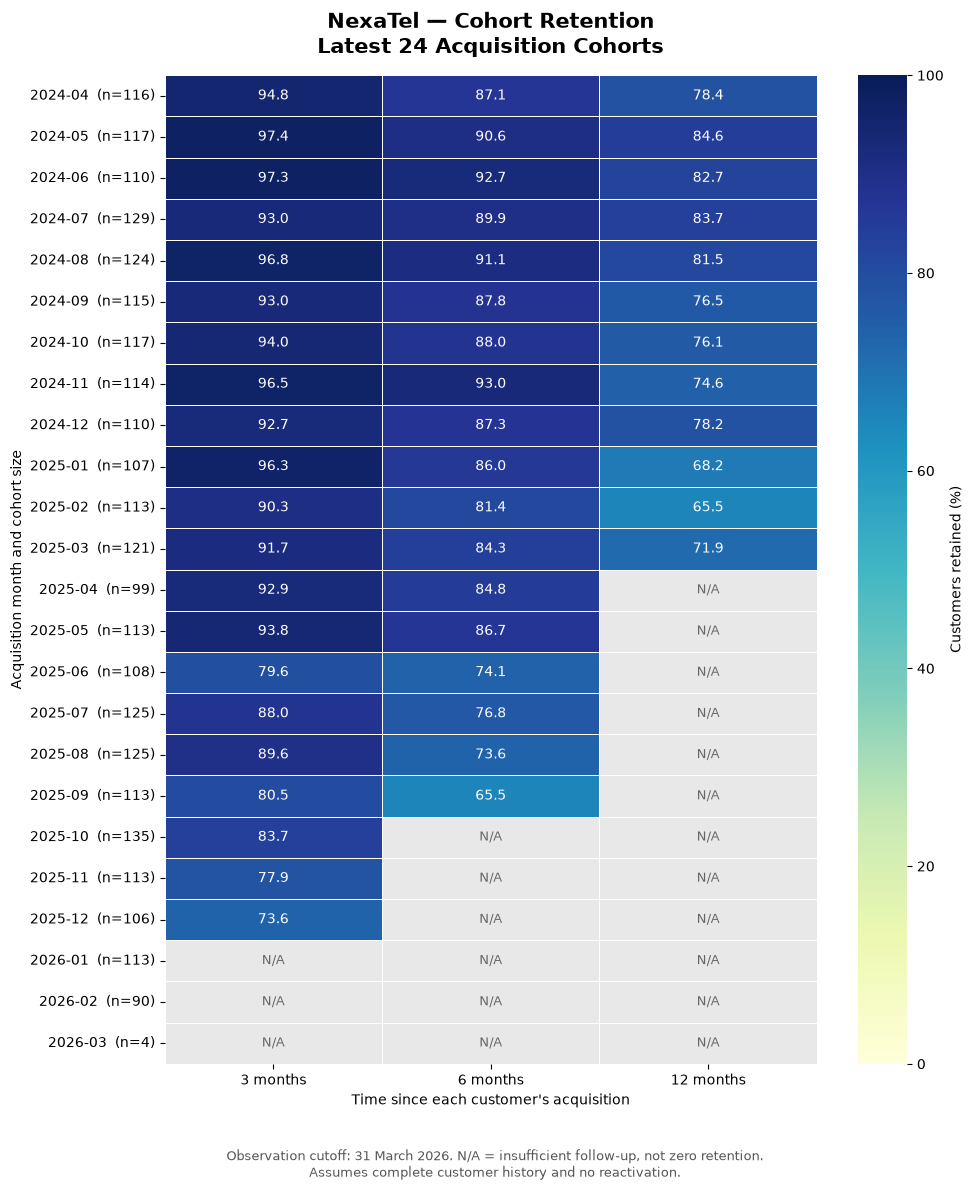

Chart saved: phase3_output\charts\11_cohort_retention_heatmap.png


In [24]:
# Step 3: Plot cohort retention for the latest 24 acquisition cohorts

import matplotlib.pyplot as plt
import seaborn as sns

retention_columns = [
    "3-month retention (%)",
    "6-month retention (%)",
    "12-month retention (%)"
]

recent_cohorts = cohort_retention_table.tail(24)
heatmap_data = recent_cohorts[retention_columns].copy()

row_labels = [
    f"{cohort}  (n={int(count):,})"
    for cohort, count in recent_cohorts["Cohort customers"].items()
]

fig, ax = plt.subplots(figsize=(10, 12))
ax.set_facecolor("#E8E8E8")

sns.heatmap(
    heatmap_data,
    mask=heatmap_data.isna(),
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    linecolor="white",
    xticklabels=["3 months", "6 months", "12 months"],
    yticklabels=row_labels,
    cbar_kws={"label": "Customers retained (%)"},
    ax=ax
)

# Explicitly label cells with insufficient follow-up.
for row in range(len(heatmap_data)):
    for col in range(len(heatmap_data.columns)):
        if pd.isna(heatmap_data.iloc[row, col]):
            ax.text(
                col + 0.5, row + 0.5, "N/A",
                ha="center", va="center",
                color="#666666", fontsize=9
            )

ax.set_title(
    "NexaTel — Cohort Retention\nLatest 24 Acquisition Cohorts",
    fontsize=15,
    fontweight="bold",
    pad=16
)
ax.set_xlabel("Time since each customer's acquisition")
ax.set_ylabel("Acquisition month and cohort size")
ax.tick_params(axis="y", labelrotation=0)
ax.tick_params(axis="x", labelrotation=0)

fig.text(
    0.5, 0.015,
    "Observation cutoff: 31 March 2026. "
    "N/A = insufficient follow-up, not zero retention.\n"
    "Assumes complete customer history and no reactivation.",
    ha="center",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.06, 1, 1])

phase3_chart_folder = output_folder / "charts"
phase3_chart_folder.mkdir(parents=True, exist_ok=True)

cohort_chart_path = (
    phase3_chart_folder / "11_cohort_retention_heatmap.png"
)

fig.savefig(cohort_chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved:", cohort_chart_path)

### Cohort Retention — Observation

Among the displayed cohorts, three-month retention was 96.26% for January 2025 compared with 73.58% for December 2025, indicating weaker early retention in the latter cohort. January 2025 retention fell from 96.26% at three months to 85.98% at six months and 68.22% at twelve months. These descriptive differences warrant investigation but do not establish their causes; N/A cells indicate insufficient follow-up through 31 March 2026, not zero retention.